<a href="https://colab.research.google.com/github/Gabriel-Moreno-Miranda-da-Silva/CN-2026/blob/main/Tarefa_Interpolacao_Erros%5B1%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

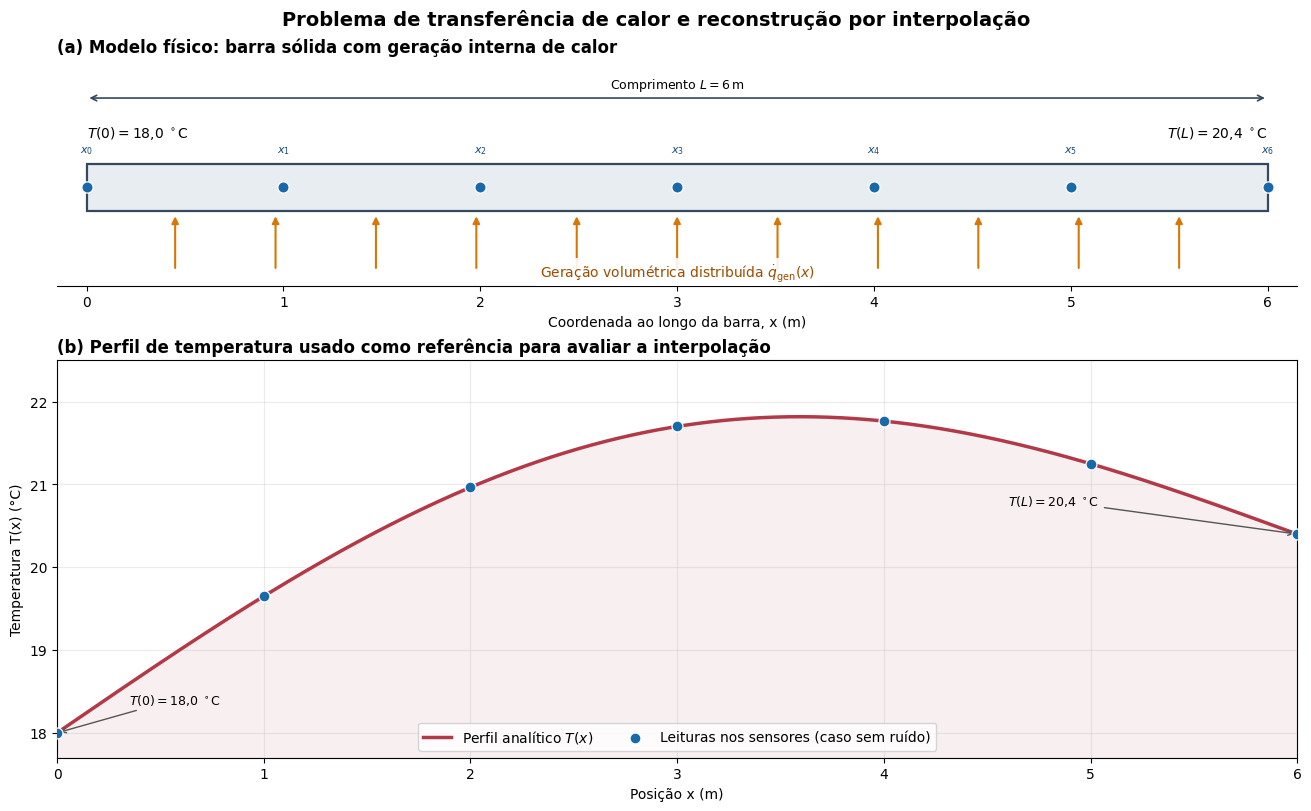

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




In [13]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)
display(metricas_7)

# TODO: calcular a tabela de métricas na malha fina
# metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
# display(metricas_7)

# TODO: sobreponha os quatro métodos à função verdadeira e marque os nós

,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


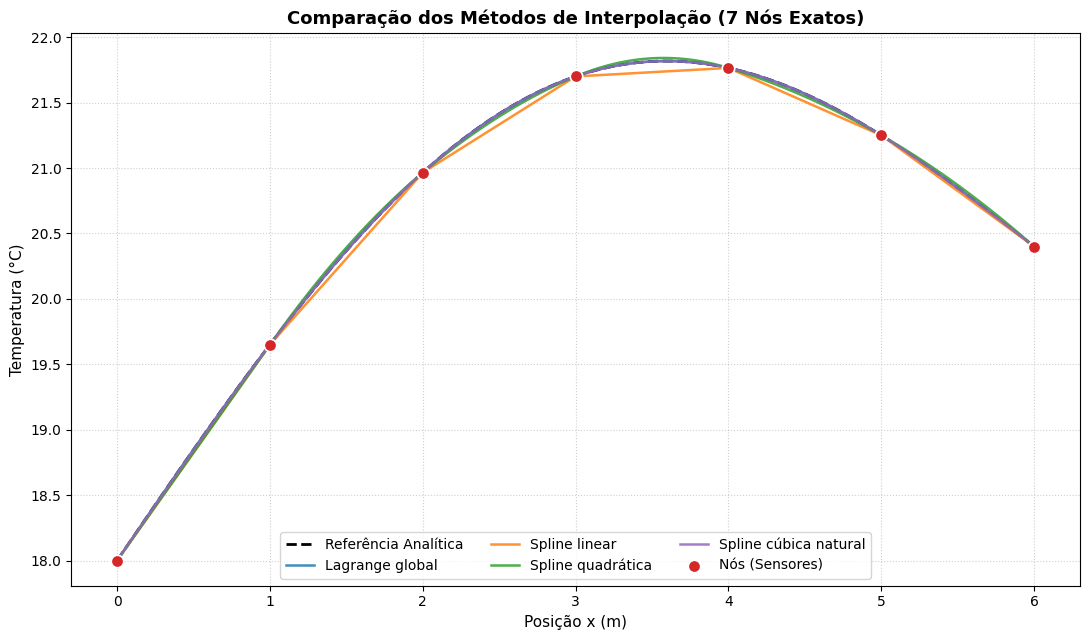

In [14]:
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)


plt.figure(figsize=(11, 6.5))
plt.plot(x_fino, T_fino, '--', color='black', linewidth=2.0, label='Referência Analítica', zorder=2)

cores = {
    'Lagrange global': '#1f77b4',
    'Spline linear': '#ff7f0e',
    'Spline quadrática': '#2ca02c',
    'Spline cúbica natural': '#9467bd'
}
for nome, metodo in metodos_7.items():
    plt.plot(x_fino, metodo(x_fino), label=nome, color=cores.get(nome, None), linewidth=1.8, alpha=0.85, zorder=3)

plt.scatter(x_nos_7, y_nos_7, color='#d62728', s=80, edgecolor='white', linewidth=1.2, label='Nós (Sensores)', zorder=4)

plt.title('Comparação dos Métodos de Interpolação (7 Nós Exatos)', fontsize=13, weight='bold')
plt.xlabel('Posição x (m)', fontsize=11)
plt.ylabel('Temperatura (°C)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower center', ncol=3, frameon=True)
plt.tight_layout()
plt.show()

In [5]:
# TODO: gráfico dos erros assinados método a método.
# Dica: erro = metodo(x_fino) - T_fino


## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

,N,Distribuição,Erro Máximo (°C),RMSE (°C)
0,5,Equiespaçada,4.530257e-03,2.159567e-03
1,5,Chebyshev-Lobatto,2.326599e-03,1.532697e-03
2,9,Equiespaçada,1.043537e-06,3.438146e-07
3,9,Chebyshev-Lobatto,2.167582e-07,1.202332e-07
4,13,Equiespaçada,5.914913e-11,1.545918e-11
5,13,Chebyshev-Lobatto,3.623768e-12,1.932084e-12
6,17,Equiespaçada,1.989520e-12,2.445428e-13
7,17,Chebyshev-Lobatto,1.421085e-14,3.917488e-15


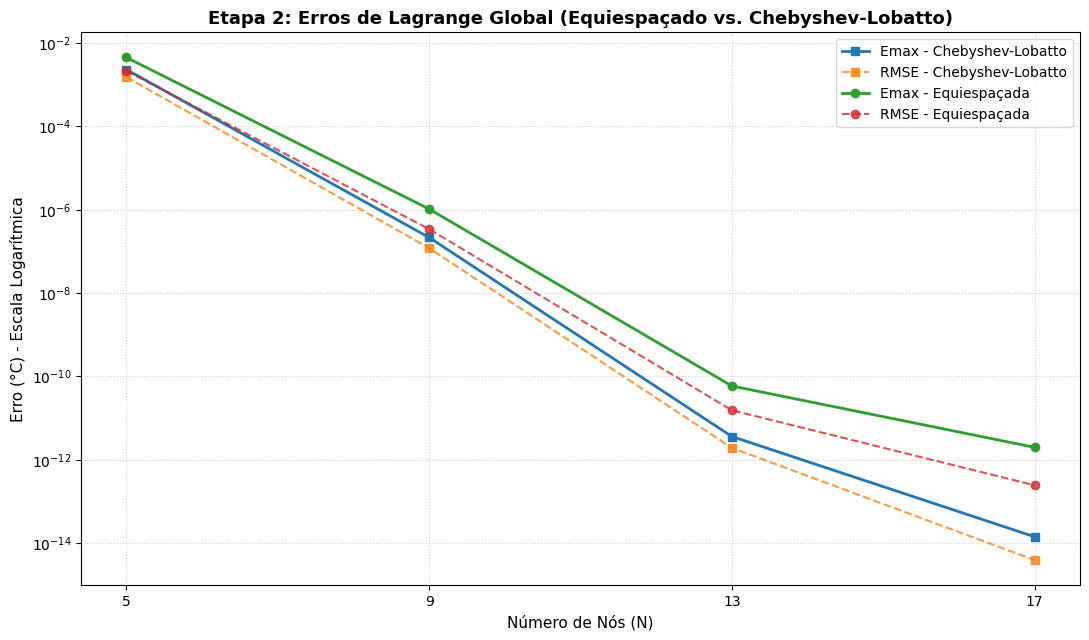

In [23]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

N_valores = [5, 9, 13, 17]
resultados = []

for N in N_valores:
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    poly_eq = BarycentricInterpolator(x_eq, y_eq)
    y_pred_eq = poly_eq(x_fino)
    erro_eq = y_pred_eq - T_fino
    emax_eq = np.max(np.abs(erro_eq))
    rmse_eq = np.sqrt(np.mean(erro_eq**2))
    resultados.append({
        'N': N,
        'Distribuição': 'Equiespaçada',
        'Erro Máximo (°C)': emax_eq,
        'RMSE (°C)': rmse_eq
    })

    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = temperatura_real(x_ch)
    poly_ch = BarycentricInterpolator(x_ch, y_ch)
    y_pred_ch = poly_ch(x_fino)
    erro_ch = y_pred_ch - T_fino
    emax_ch = np.max(np.abs(erro_ch))
    rmse_ch = np.sqrt(np.mean(erro_ch**2))
    resultados.append({
        'N': N,
        'Distribuição': 'Chebyshev-Lobatto',
        'Erro Máximo (°C)': emax_ch,
        'RMSE (°C)': rmse_ch
    })

tabela_nos = pd.DataFrame(resultados)
display(tabela_nos)

plt.figure(figsize=(11, 6.5))

for dist, grupo in tabela_nos.groupby('Distribuição'):
    marcador = 'o' if dist == 'Equiespaçada' else 's'
    plt.plot(grupo['N'], grupo['Erro Máximo (°C)'], marker=marcador, linestyle='-', linewidth=2, label=f'Emax - {dist}')
    plt.plot(grupo['N'], grupo['RMSE (°C)'], marker=marcador, linestyle='--', linewidth=1.5, alpha=0.8, label=f'RMSE - {dist}')

plt.yscale('log')
plt.xlabel('Número de Nós (N)', fontsize=11)
plt.ylabel('Erro (°C) - Escala Logarítmica', fontsize=11)
plt.title('Etapa 2: Erros de Lagrange Global (Equiespaçado vs. Chebyshev-Lobatto)', fontsize=13, weight='bold')
plt.xticks(N_valores)
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(loc='best', frameon=True)
plt.tight_layout()
plt.show()

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

,N,Distribuição,Erro Máximo (°C),RMSE (°C)
0,2,Lagrange (Equiespaçado),2.500000,1.767325
1,2,Lagrange (Chebyshev-Lobatto),2.500000,1.767325
2,2,Spline Cúbica Natural,2.500000,1.767325
3,3,Lagrange (Equiespaçado),0.140024,0.089568
4,3,Lagrange (Chebyshev-Lobatto),0.140024,0.089568
5,3,Spline Cúbica Natural,0.050043,0.033532
6,4,Lagrange (Equiespaçado),0.109039,0.068296
7,4,Lagrange (Chebyshev-Lobatto),0.142977,0.080945
8,4,Spline Cúbica Natural,0.010177,0.004787
9,5,Lagrange (Equiespaçado),0.004530,0.002160


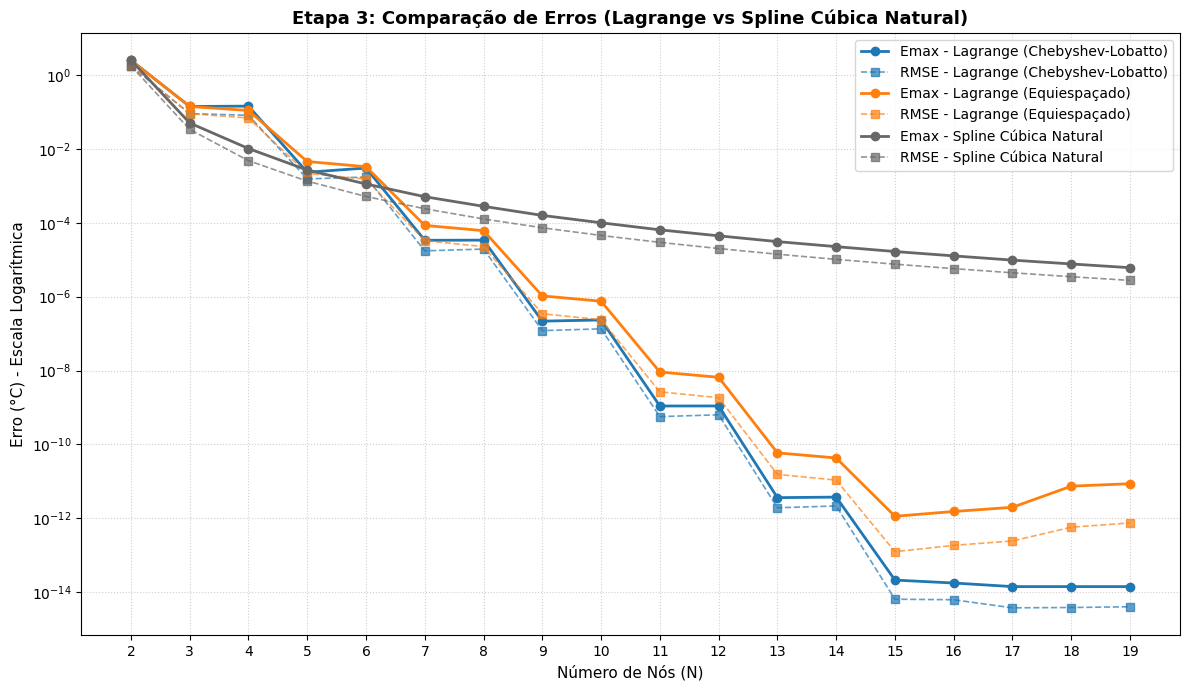

In [32]:
N_valores = list(range(2, 20))
resultados = []

for N in N_valores:
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    poly_eq = BarycentricInterpolator(x_eq, y_eq)
    y_pred_eq = poly_eq(x_fino)
    erro_eq = y_pred_eq - T_fino
    resultados.append({
        'N': N,
        'Distribuição': 'Lagrange (Equiespaçado)',
        'Erro Máximo (°C)': np.max(np.abs(erro_eq)),
        'RMSE (°C)': np.sqrt(np.mean(erro_eq**2))
    })

    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = temperatura_real(x_ch)
    poly_ch = BarycentricInterpolator(x_ch, y_ch)
    y_pred_ch = poly_ch(x_fino)
    erro_ch = y_pred_ch - T_fino
    resultados.append({
        'N': N,
        'Distribuição': 'Lagrange (Chebyshev-Lobatto)',
        'Erro Máximo (°C)': np.max(np.abs(erro_ch)),
        'RMSE (°C)': np.sqrt(np.mean(erro_ch**2))
    })

    x_sc = np.linspace(x_min, x_max, N)
    y_sc = temperatura_real(x_sc)
    poly_sc = CubicSpline(x_sc, y_sc, bc_type='natural')
    y_pred_sc = poly_sc(x_fino)
    erro_sc = y_pred_sc - T_fino
    resultados.append({
        'N': N,
        'Distribuição': 'Spline Cúbica Natural',
        'Erro Máximo (°C)': np.max(np.abs(erro_sc)),
        'RMSE (°C)': np.sqrt(np.mean(erro_sc**2))
    })


tabela_nos = pd.DataFrame(resultados)
display(tabela_nos.head(10))

plt.figure(figsize=(12, 7))

cores_metodos = {
    'Lagrange (Equiespaçado)': '#ff7f0e',
    'Lagrange (Chebyshev-Lobatto)': '#1f77b4',
    'Spline Cúbica Natural': '#676767'
}

for dist, grupo in tabela_nos.groupby('Distribuição'):
    cor = cores_metodos.get(dist, None)
    plt.plot(grupo['N'], grupo['Erro Máximo (°C)'], marker='o', linestyle='-', linewidth=2, color=cor, label=f'Emax - {dist}')
    plt.plot(grupo['N'], grupo['RMSE (°C)'], marker='s', linestyle='--', linewidth=1.2, alpha=0.7, color=cor, label=f'RMSE - {dist}')

plt.yscale('log')
plt.xlabel('Número de Nós (N)', fontsize=11)
plt.ylabel('Erro (°C) - Escala Logarítmica', fontsize=11)
plt.title('Etapa 3: Comparação de Erros (Lagrange vs Spline Cúbica Natural)', fontsize=13, weight='bold')
plt.xticks(np.arange(2, 20, 1))
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(loc='best', frameon=True, ncol=1)
plt.tight_layout()
plt.show()

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

Ao tratar com poucos sensores, a Spline Cúbica Natural se mostrou mais eficiente, em um intervalo de 2 a 6, em que ambos os erros foram menores que as outras opções, entretanto, quando o intervalo ultrapassa o valor máximo de 6, as funções Lagrange equiespaçado e Lagrange com Chebyshev tem o erro muito menor, já que o Spline é exponencialmente decrescente, e as outras tem o erro caindo muito mais rápido, embora a de Lagrange com Chebyshev o erro começa a aumentar exponencialmente se muitos sensores forem colados.

A análise anterior foi feita supondo um ambiente sem ruído, se levar em conta os possíveis ruídos, a Spline Cúbica Natural irá apresentar menos distorção nos resultados, por ser um método muito mais constante, em que pequenos ruídos não farão grandes alterações no resultado das amostras.

Ao se aproximar das extremidades, as funções apresentam variações, deve-se colocar sensores próximos das extremidades para que fique estável.

Se a temperatura for desconhecida, não poderá calcular a diferença(erro) entre as estimativas dada pelas funções e a temperatura real, portanto, não tem como medir se a estimativa foi precisa.


